# Homework 1 – Your corpus: duplicates & completeness
*MIR & ML for Audio · TU Berlin · WiSe 2026/27*

Please fill out: 
| | |
|---|---|
| **Name** | Hallvard Jensen |
| **Student ID** | 0549158 |
| **Corpus (genre)** | Nu Disco/Disco |

**Submission:** work in this notebook – code, figures and text answers all stay here.

Before uploading: **Restart Kernel & Run All**, check that every output is shown, then upload this `.ipynb` file along with the graphics/plots.

## Tasks
1. Choose a practice corpus (Beatport charts 2013–2023 of one EDMC genre) from 19 genres – as individual as possible:
   afro house · breaks / breakbeat / UK bass · dance / electro-pop · deep house · drum'n'bass · dubstep · electronica · hard dance / hardcore · house · indie dance · melodic house / techno · minimal / deep tech · nu disco / disco · psytrance · tech house · techno · trance (main floor) · trap / wave · UK garage / bassline
2. Download your corpus (CSV and Top 100 preview MP3s per year): https://tubcloud.tu-berlin.de/s/pgpibnbNfSF5jnM
3. Create a duplicate-free preview folder for all years (`previews/`).
4. Based on the CSV file, create statistics and visualisations of the **completeness of metadata and audio data per chart year** for your corpus.

---
## Setup
Expected project structure (relative to this notebook):
```
<course folder>/                                
├── HW01_corpus_completeness.ipynb
├── data/
│   └── <your-genre>/
│       ├── <genre>.csv
│       ├── previews/          ← task 3
│       └── 2013/top100/ … 2023/top100/
└── output/                    ← figures & tables
```

In [202]:
# import standard packages you'll need

import sys
import shutil
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

print(sys.executable)
print("pandas", pd.__version__)

# ─ add your own additional imports here:
from datetime import datetime

/home/hallvard/miniforge3/envs/mirml/bin/python
pandas 3.1.0


In [203]:
# ── CONFIG ───────────────────────────────────────────────────────────────
CORPUS_DIR = Path("data") / "nu-disco-disco"   # ← name of your corpus folder
# ─────────────────────────────────────────────────────────────────────────
PREVIEW_DIR = CORPUS_DIR / "previews"
OUTPUT_DIR = Path("output")
OUTPUT_DIR.mkdir(exist_ok=True)

assert CORPUS_DIR.is_dir(), f"Not found: {CORPUS_DIR.resolve()} → check CORPUS_DIR"
CHART_CSV = next(CORPUS_DIR.glob("*.csv"))
print(CHART_CSV)

data/nu-disco-disco/Nu_Disco_Disco.csv


---
## Tasks 1 + 2 · Corpus
Fill in your genre in the table at the top and set `CORPUS_DIR` in the CONFIG cell.

Please make sure that you choose an unclaimed genre, there should be one for each! 

---
## Task 3 · Duplicate-free `previews/` folder

In [204]:
# Task 3: create previews/
all_mp3s = sorted(CORPUS_DIR.glob("*/top100/*.mp3"))
ids = pd.Series(all_mp3s)

PREVIEW_DIR.mkdir(exist_ok=True)
for song_id in ids.tolist():
    dst = PREVIEW_DIR / song_id.name
    if not dst.exists():
        shutil.copy2(song_id, dst)


In [205]:
# Task 3: check your result
preview_ids = pd.Series([p.stem for p in PREVIEW_DIR.glob("*.mp3")])
all_ids = pd.Series([p.stem for p in all_mp3s])
print(f"Total ids found: {all_ids.count()}")
print(f"Unique ids found: {all_ids.nunique()}")
print(f"Duplicates: {all_ids.count()-all_ids.nunique()}")
print(f"Total ids in preview/: {preview_ids.count()}")
print(f"Unique ids in preview/: {preview_ids.nunique()}")

Total ids found: 464
Unique ids found: 315
Duplicates: 149
Total ids in preview/: 315
Unique ids in preview/: 315


### Answer 3
*Briefly describe your approach and your result (numbers).*

In the first code block I collect all found mp3 paths, create the previews directory, and iterate over all found paths and copy them to previews. Uniqueness check is done simply by checking if the filename already exists in previews/. This is necessary, since we need the complete relative path to the original mp3 file to be able to copy it to previews/.

In the checking code block I make two series with only ids for the contents of previews/ and all ids found in the data set. Then I compare the found ids, how many uniques and duplicates with what is found in previews/. We see here that 464 ids were found, with 149 duplicates, which makes 315 uniques. In preview we have 315 entries and all 315 are unique, which means all unique ids have been copied.

---
## Task 4 · Completeness per chart year
### 4.1 Load & inspect the chart table

In [370]:
# Task 4.1: load & inspect
charts = pd.read_csv(CHART_CSV)
print(charts.shape) 
print(charts.head())
# print(charts.info())

# Normalize all null values to NaN
clean = charts.copy()
clean = clean.replace(
    {
        0: np.nan,
        "": np.nan,
    }
)
clean = clean.replace(r"^\s*$", np.nan, regex=True)

missing = clean.isna().sum()
print("Columns with zero, empty, or NaN values:")
print(missing)

(3813, 14)
   year  rank  points  days_charted  beatport_track_id  \
0  2019     1   11313           116           12210204   
1  2019     2   11107           116           12360939   
2  2019     3   10736           116           12310558   
3  2019     4   10490           116           12441066   
4  2019     5   10130           102           12521466   

                         title                                       mix  \
0                      Emotion                              Extended Mix   
1             Express Yourself                              Original Mix   
2                          NaN                                       NaN   
3  Heaven feat. Andreya Triana  Mousse T.'s Disco Shizzle Extended Remix   
4                         Joys       Purple Disco Machine Extended Remix   

                                  artist         label  duration_ms subgenre  \
0                   Purple Disco Machine    Club Sweat     369674.0      NaN   
1                      

### 4.2 Completeness of metadata per chart year

In [334]:
# Task 4.2: statistics

unusual_years = ~clean.year.between(2019, 2023)
print(f"\nRows with year outside range 2019-2023: {unusual_years.sum()}")

print("\nNumber of unique tracks per year:")
unique_tracks = clean.groupby("year").beatport_track_id.nunique()
print(unique_tracks.to_string())

print(
    f"\nThere are only {charts.subgenre.notna().sum()} tracks with non-null subgenres."
)
print("The only found subgenres are: ")
print(clean.dropna().groupby("year").subgenre.unique().to_string())

unusual_bpm = clean.bpm.notna() & ~charts.bpm.between(50, 200)
print("\nTracks with unusual BPMs per year:")
print(
    clean.loc[unusual_bpm]
    .groupby(["year", "bpm"])
    .title.apply(list)
    .to_string()
)

# Convert string format string to datetime
clean.release_date = pd.to_datetime(clean.release_date)

date = datetime(year=2000, month=1, day=1)
date_mask = clean.release_date < date

print(f"\nNumber of charting tracks with release date before {date.year}:")
print(clean.loc[date_mask].groupby("year").size().to_string())


duration_mask = ~clean.duration_ms.between(1000 * 60 * 2, 1000 * 60 * 8)
print(f"\nDuration less than 2 minutes or more than 8 minutes:")
print(
    clean.dropna()
    .loc[duration_mask, ["year", "title", "duration_ms"]]
    .groupby(["year", "duration_ms"])
    .title.apply(list)
    .to_string()
)



Rows with year outside range 2019-2023: 0

Number of unique tracks per year:
year
2019    393
2020    936
2021    873
2022    819
2023    792

There are only 52 tracks with non-null subgenres.
The only found subgenres are: 
year
2019    [Dark Disco, Funk / Soul]
2020    [Funk / Soul, Dark Disco]
2021         [Italo, Funk / Soul]
2022         [Funk / Soul, Italo]
2023         [Funk / Soul, Italo]

Tracks with unusual BPMs per year:
year  bpm  
2022  240.0    [The Night, She Got Everything]

Number of charting tracks with release date before 2000:
year
2019    2
2022    1
2023    2

Duration less than 2 minutes or more than 8 minutes:
year  duration_ms
2019  511315.0        [Another Man]
2020  633262.0       [Back To Life]


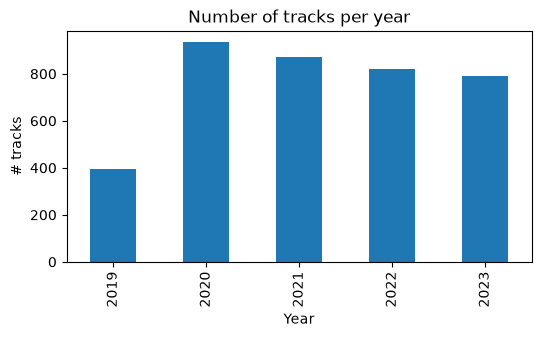

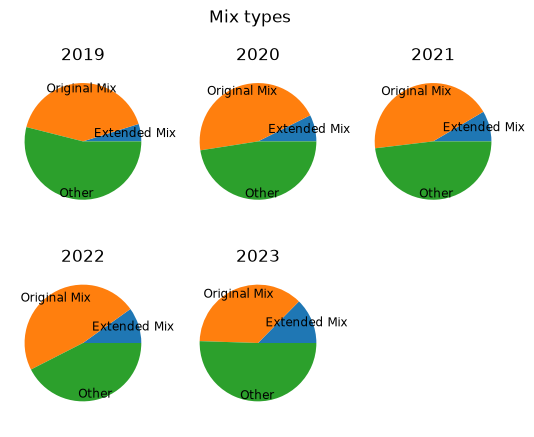

In [472]:
# Task 4.2: visualisation
# fig, ax = plt.subplots()
# ax.bar(clean.year, unique_tracks, use_index=True)
ax = unique_tracks.plot(figsize=(6, 3), kind="bar")
ax.set(xlabel="Year", ylabel="# tracks", title="Number of tracks per year")
ax.figure.savefig(OUTPUT_DIR / "tracks-per-year.png", bbox_inches="tight")
plt.show()

# Plot different mixes
mix_copy = clean.copy()
mix_copy.loc[~mix_copy.mix.isin(["Extended Mix", "Original Mix"]), "mix"] = (
    "Other"
)
s = mix_copy.groupby(["year", "mix"]).size()
row = 2
col = 3
fig, axs = plt.subplots(row, col)
fig.suptitle("Mix types")
axs[-1][-1].axis("off")
for i, year in enumerate(s.groupby(level=0)):
    c = i % col
    r = i // col
    pie = axs[r][c].pie(year[1])
    axs[r][c].pie_label(
        pie,
        year[1].index.get_level_values(1),
        distance=0.9,
        textprops={"fontsize": "small"},
    )
    axs[r][c].set(title=year[0])
fig.savefig(OUTPUT_DIR / "mix-types.png", bbox_inches="tight")
plt.show()

### 4.3 Completeness of audio data per chart year

In [111]:
# Task 4.3: statistics
for year in charts["year"].unique():
    n = charts.where(lambda c: c.year == year)
    print(f"year={year}, n={n.beatport_track_id.count()}")
    # print(f"year={year}, num={len(n)}")
# charts.where(lambda x: x.year == 2019).count()

year=2019, n=393
year=2020, n=936
year=2021, n=873
year=2022, n=819
year=2023, n=792


In [ ]:
# Task 4.3: visualisation

### Answer 4
*Describe your approach (what did you count as missing? absolute or relative values? which reference?) and summarise your main findings.*

No occurrences of "unknown", "nan", "null", "none", "0"
Only weird entries were the empty ones

---
## Before you upload
- [ ] Name, student ID and genre filled in
- [ ] **Restart Kernel & Run All** runs without errors, all outputs visible
- [ ] Figures labelled (axes, units, title)